# 04 · Modelos del esfuerzo mecánico: ¿cuánto explica el MC4 frente al Skinpass?

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 4 (modelado), problema A

## A. Contexto de la etapa

**¿Qué investigamos?** La pregunta central de la tesis, parte A: una vez controlado por producto, **¿en qué medida** la herencia del MC4 (geometría, temperatura, espera entre líneas), frente a las condiciones del propio Skinpass (rodillos, setup, operador, turno), explica el esfuerzo del Skinpass y su desviación frente al preset?

**Respuestas** (Notebooks 01-02, aprobadas):
- **ΔBending** (principal): varía casi todo dentro de producto.
- **ΔFuerza**: el producto explica el 84 %; se analiza lo que queda.
- **Bending real** y **fuerza real** en paralelo: si el MC4 mueve el valor real pero no el Δ, el setup ya lo anticipa.

**Lo que esperamos, por el Notebook 02:** poca contribución del MC4 a ΔBending, una contribución visible de los días de espera a ΔFuerza, y un peso importante del turno o la campaña del Skinpass.

## B. Fundamento conceptual

**1. Modelos anidados y partición de la varianza.** Ajustamos el mismo modelo con conjuntos crecientes de predictores:

| Modelo | Predictores |
|---|---|
| M1 | Controles (producto, dimensiones, orden) |
| M2 | M1 + bloque MC4 |
| M3 | M1 + bloque Skinpass |
| M4 | M1 + MC4 + Skinpass (+ interacciones) |

- **Aporte propio del MC4** = R²(M4) − R²(M3): lo que el MC4 agrega cuando el Skinpass ya está en el modelo.
- **Aporte propio del Skinpass** = R²(M4) − R²(M2).
- **Aporte compartido** = lo que cualquiera de los dos explica, pero no se puede asignar a uno solo, porque se mueven juntos.

Esto responde directamente el "¿en qué medida?".

**2. Modelo lineal mixto (LMM).** Un modelo lineal con dos tipos de efectos:
- **Efectos fijos:** pendientes de las variables (por ejemplo, cuántos kN cambia ΔBending por cada desviación estándar de corona).
- **Efectos aleatorios:** un desplazamiento propio de cada grupo (cada programa del Skinpass), que se estima "encogido" hacia la media global: un grupo con pocas piezas se acerca más a la media que uno con muchas.

La proporción de varianza que se debe al grupo se llama **ICC** (correlación intraclase). Para comparar modelos usamos el **R² marginal** (lo que explican los efectos fijos) y el **R² condicional** (efectos fijos + grupo), según Nakagawa y Schielzeth.

*Limitación de herramienta:* statsmodels ajusta bien un efecto aleatorio a la vez. Los dos programas (MC4 y SKP) están cruzados (Notebook 00), así que estimamos el ICC de cada uno por separado y usamos el Programa SKP como efecto aleatorio del modelo principal, porque es el que más explica ΔBending (Notebook 01).

**3. GBDT (LightGBM).** Suma cientos de árboles de decisión pequeños, cada uno corrigiendo los errores de los anteriores. Captura **no linealidades** (por ejemplo, el escalón de los días de espera) e **interacciones** sin que haya que escribirlas. Usamos LightGBM porque:
- maneja faltantes sin imputar;
- acepta variables categóricas con muchos niveles (818 productos);
- es rápido con 43 mil piezas.

**4. Validación cruzada agrupada.** El R² de GBDT se mide **fuera de muestra**: se entrena con 4 pliegues y se predice el quinto, con pliegues por Programa MC4 (Notebook 03). El periodo de prueba (noviembre-diciembre) **no se usa** aquí.

**5. R² dentro de producto.** Para ΔFuerza, el producto solo explica el 84 %, así que un R² total alto no dice nada del MC4. Reportamos también cuánto **mejora el modelo sobre saber solo la media del producto**:

$$R^2_{\text{dentro}} = 1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y_{\text{producto}(i)})^2}$$

donde la media del producto se calcula con los **otros pliegues**, igual que la predicción del modelo. Un valor de 0 significa "no mejora nada sobre conocer el producto"; uno negativo, que el modelo predice peor que esa media.

**6. SHAP.** Reparte la predicción de cada pieza entre las variables, de forma que la suma de las contribuciones dé exactamente la predicción. Sumando el |SHAP| por bloque obtenemos la **importancia de cada bloque**. Es importancia **predictiva**, no causal: dice en qué se apoya el modelo, no qué pasaría si cambiáramos esa variable en planta.

## C. Objetivo y metodología

1. **Cuánto explica cada agrupación** (programa SKP, programa MC4, campaña) dentro de producto: ICC con LMM nulos.
2. **LMM anidados** M1-M4 para ΔBending y ΔFuerza (dentro de producto, efecto aleatorio por programa SKP): R² marginal y condicional y coeficientes con intervalo.
3. **GBDT anidados** M1-M4 para las cuatro respuestas, con R² fuera de muestra (total y dentro de producto) y aportes propio y compartido.
4. **SHAP por bloque** en el modelo completo.
5. **Respuesta a la pregunta de la tesis**, parte A.

**Bloques de predictores** (todos del Notebook 03; ninguno se conoce después del Skinpass):

| Bloque | Variables |
|---|---|
| Controles | producto, espesor, ancho, espesor nominal final, peso de entrada, dividido, reproceso, holgura de peso |
| MC4 | geometría (corona relativa, acuñamiento, taper, errores de espesor y ancho, posición en tolerancia, canteo R1/R2, offset), térmica (errores de enrollado y acabado, enrollado frío y fuera de rango, T en F1, caída F1→F7, asimetría, loopers, descarga, estancia, cubierta) y **espera** (días MC4 → SKP) |
| Skinpass | piezas en campaña, diámetros, diferencia de pareja, corona del rodillo, apoyo superior, riesgo de spring back, operador; y el **preset** (setup) solo para las respuestas reales (ver sección 1.1) |

## D. Implementación
### 0. Configuración

In [1]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        # La copia de Colab es desechable: se iguala a GitHub aunque tenga figuras o archivos regenerados.
        subprocess.run(['git', '-C', REPO, 'fetch', '-q', 'origin', 'main'], check=True)
        subprocess.run(['git', '-C', REPO, 'reset', '-q', '--hard', 'origin/main'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [2]:
import sys, warnings
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import lightgbm as lgb
import shap
from src.ternium import *

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', module='statsmodels')
estilo()
pd.set_option('display.max_columns', 30, 'display.width', 170)
RESULTADOS = RAIZ / 'resultados'; RESULTADOS.mkdir(exist_ok=True)
SEMILLA = 2025

/Users/diego/.pyenv/versions/3.9.13/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1. Datos: población A, solo entrenamiento
La prueba final (noviembre-diciembre) no se toca. Trabajamos con las piezas de la población A en entrenamiento y sus 5 pliegues por Programa MC4.

In [3]:
B = cargar_base_analitica()
d = B[(B['pob_A'] == 1) & (~B['en_prueba'])].reset_index(drop=True)
print(f"Población A en entrenamiento: {len(d):,} piezas · {d['producto'].nunique()} productos · "
      f"{d['programa_skp'].nunique()} programas SKP · {d['programa_mc4'].nunique()} programas MC4")

CONTROLES = ['espesor_mm', 'ancho_mm', 'espesor_final_nominal_mm', 'peso_entrada_t', 'dividido', 'es_reproceso', 'holgura_peso_pct']
MC4_GEO = ['corona_relativa_pct', 'acunamiento_um', 'taper_medido', 'error_espesor_um', 'error_ancho_mm', 'posicion_tol_ancho',
           'canteo_r1', 'canteo_r2', 'offset_ancho_manual_aplicado']
MC4_TER = ['error_t_enrollado_c', 'enrollado_frio', 'enrollado_fuera_rango', 'error_t_acabado_c', 't_f1_c', 'caida_f1_f7_c',
           'asimetria_acabador_c', 'looper_media_mpa', 'looper_max_mpa', 't_descarga_horno_c', 'tiempo_estancia_horno',
           'cubierta_termica_pct']
ESPERA = ['dias_mc4_skp']
MC4 = MC4_GEO + MC4_TER + ESPERA
SKP = ['piezas_en_campana', 'diametro_rodillo_mm', 'dif_diametro_pareja_mm', 'corona_rodillo', 'diametro_apoyo_sup_mm',
       'riesgo_spring_back']
FALTA = [c for c in B.columns if c.endswith('_falta')]
PRESET = {'delta_bending': 'preset_bending', 'bending_real': 'preset_bending',
          'delta_fuerza': 'preset_fuerza', 'fuerza_real': 'preset_fuerza'}
RESPUESTAS = ['delta_bending', 'bending_real', 'delta_fuerza', 'fuerza_real']
NOMBRE = {'delta_bending': 'ΔBending', 'bending_real': 'Bending real', 'delta_fuerza': 'ΔFuerza', 'fuerza_real': 'Fuerza real'}
BLOQUE = {**{c: 'Controles' for c in CONTROLES + ['producto']}, **{c: 'MC4 geometría' for c in MC4_GEO},
          **{c: 'MC4 térmica' for c in MC4_TER}, **{c: 'Espera MC4→SKP' for c in ESPERA},
          **{c: 'Skinpass' for c in SKP + ['usuario_skp']},
          **{c: 'Setup (preset)' for c in ['preset_bending', 'preset_fuerza']}}
REALES = ['bending_real', 'fuerza_real']      # solo estas respuestas usan el preset como predictor (sección 1.1)

Población A en entrenamiento: 43,175 piezas · 666 productos · 588 programas SKP · 1385 programas MC4


### 1.1 Una trampa antes de modelar: el preset está dentro del Δ
ΔBending = bending real − preset. Si el preset se usa como **predictor** de ΔBending, el modelo puede "explicar" el Δ solo con el preset, aunque el bending real no dependa de nada: es un **acoplamiento matemático** (la respuesta contiene al predictor). En una primera versión de este notebook, el bloque Skinpass parecía explicar el 73 % de ΔBending, y casi todo venía del preset.

Lo medimos directamente: ¿cuánto sigue el valor real a su preset, dentro de un mismo producto? Si el real siguiera al preset uno a uno (pendiente 1), el Δ no tendría relación con el preset.

In [4]:
def dentro(df, c):
    return df[c] - df.groupby('producto')[c].transform('mean')
seg = []
for preset, real, delta in [('preset_bending', 'bending_real', 'delta_bending'), ('preset_fuerza', 'fuerza_real', 'delta_fuerza')]:
    xp, yr, yd = dentro(d, preset), dentro(d, real), dentro(d, delta)
    ok = xp.notna() & yr.notna()
    pend = np.polyfit(xp[ok], yr[ok], 1)[0]
    seg.append({'variable': real.replace('_real', ''), 'pendiente real ~ preset (dentro)': pend,
                'corr. real-preset (dentro)': xp[ok].corr(yr[ok]), 'corr. Δ-preset (dentro)': xp[ok].corr(yd[ok]),
                'DE del preset dentro de producto': xp.std()})
seg = pd.DataFrame(seg).set_index('variable')
seg.round(3).to_csv(RESULTADOS / '04_seguimiento_preset.csv')
seg.round(2)

,pendiente real ~ preset (dentro),corr. real-preset (dentro),corr. Δ-preset (dentro),DE del preset dentro de producto
variable,,,,
bending,0.40,0.54,-0.69,204.43
fuerza,0.71,0.71,-0.38,642.61


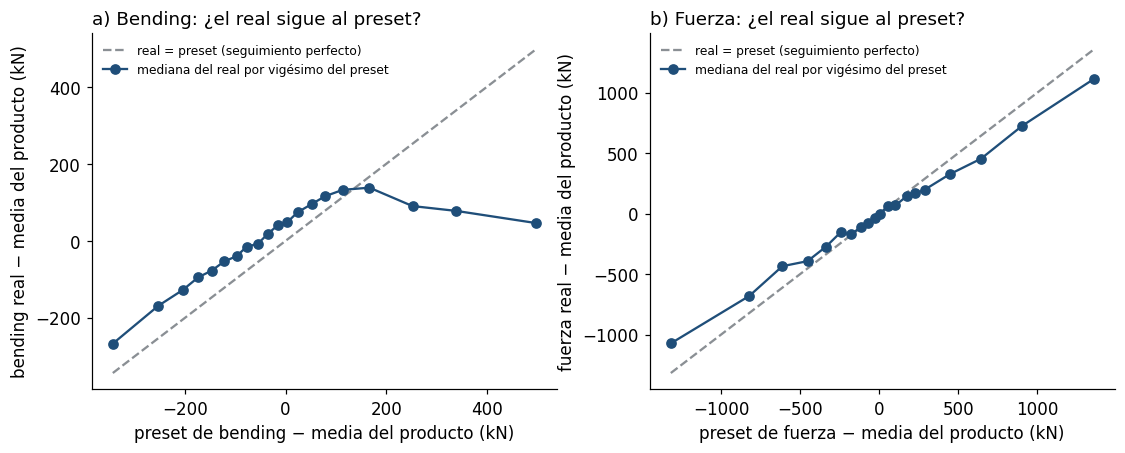

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (preset, real, nom) in zip(ax, [('preset_bending', 'bending_real', 'Bending'), ('preset_fuerza', 'fuerza_real', 'Fuerza')]):
    xp, yr = dentro(d, preset), dentro(d, real)
    ok = xp.notna() & yr.notna()
    q = pd.qcut(xp[ok].rank(method='first'), 20, labels=False)
    gg = pd.DataFrame({'x': xp[ok], 'y': yr[ok]}).groupby(q).median()
    lim = [gg.x.min(), gg.x.max()]
    a.plot(lim, lim, ls='--', color=COLORES['gris'], label='real = preset (seguimiento perfecto)')
    a.plot(gg.x, gg.y, 'o-', color=COLORES['azul'], label='mediana del real por vigésimo del preset')
    a.set_xlabel(f'preset de {nom.lower()} − media del producto (kN)'); a.set_ylabel(f'{nom.lower()} real − media del producto (kN)')
    a.set_title(f'{"ab"[ax.tolist().index(a)]}) {nom}: ¿el real sigue al preset?'); a.legend(fontsize=8)
guardar(fig, '04_seguimiento_preset'); plt.show()

**Decisión.** En los modelos de **ΔBending y ΔFuerza el preset no entra como predictor**: ya está dentro de la respuesta. En los modelos de **bending real y fuerza real** el preset entra como bloque aparte, **Setup**, porque es una decisión que existe antes de procesar la pieza.

**Qué observamos.**
- **Fuerza:** el real sigue al preset con pendiente 0.71 (correlación 0.71). Cuando el setup pide 100 kN más, el real sube ~71 kN. El seguimiento es razonable.
- **Bending:** pendiente de solo 0.40 (correlación 0.54). La gráfica muestra por qué: el real sigue al preset hasta ~+150 kN por encima de lo normal para el producto, y **ahí se satura** e incluso baja. Cuando el setup pide mucho bending, la línea no lo aplica.
- Por eso ΔBending y el preset tienen correlación −0.69: buena parte del Δ es "lo que el setup pidió y no se aplicó".

**Implicación para la intervención B (feedforward sobre el preset de bending).** Subir el preset por encima de cierto nivel **no cambia el bending real**. Antes de proponer ajustes del preset hay que saber por qué se satura: un límite del actuador, un tope del control o una corrección del operador. Es una pregunta para la planta.

### 2. Modelo lineal mixto
**Preparación (solo con estos datos de entrenamiento):**
1. Faltantes → mediana del producto (si el producto no tiene dato, la mediana global). Las banderas `_falta` del Notebook 03 entran como predictores.
2. Respuesta y predictores continuos se **centran por producto**: el modelo trabaja dentro de producto.
3. Los predictores se **estandarizan**: cada coeficiente se lee como "kN por cada desviación estándar de la variable".

#### 2.1 ¿Cuánto pesa cada agrupación? (ICC de modelos nulos)

In [6]:
def preparar_lineal(df, cols):
    x = df[cols].copy()
    x = x.fillna(df.groupby('producto')[cols].transform('median')).fillna(df[cols].median())
    return x

CONT = CONTROLES + MC4 + SKP + ['preset_bending', 'preset_fuerza']
lm = d[['producto', 'programa_skp', 'programa_mc4', 'campana', 'usuario_skp'] + RESPUESTAS + FALTA].copy()
lm[CONT] = preparar_lineal(d, CONT)
centrar = CONT + RESPUESTAS
lm[centrar] = lm[centrar] - lm.groupby('producto')[centrar].transform('mean')
escala = lm[CONT].std().replace(0, 1)
lm[CONT] = lm[CONT] / escala
lm['campana'] = lm['campana'].astype(str)
CONSTANTES = [c for c in CONT + FALTA if lm[c].std() == 0]
print('Variables sin variación en esta población (no entran al modelo lineal):', CONSTANTES)

def icc(resp, grupo):
    m = smf.mixedlm(f'{resp} ~ 1', lm, groups=lm[grupo]).fit(reml=True)
    vg, ve = float(m.cov_re.iloc[0, 0]), m.scale
    return vg / (vg + ve)

tab_icc = pd.DataFrame({NOMBRE[r]: {g: icc(r, g) for g in ['programa_skp', 'campana', 'programa_mc4']}
                        for r in ['delta_bending', 'delta_fuerza']}).T * 100
tab_icc.columns = ['Programa SKP', 'Campaña de rodillo', 'Programa MC4']
tab_icc.round(1)

Variables sin variación en esta población (no entran al modelo lineal): ['es_reproceso']


,Programa SKP,Campaña de rodillo,Programa MC4
ΔBending,23.7,25.0,9.1
ΔFuerza,32.4,20.7,19.3


**Cómo leerlo.** Cada celda es el porcentaje de la varianza **dentro de producto** que se debe a diferencias entre grupos (el ICC). Un ICC de 25 % por programa del Skinpass significa que una cuarta parte de lo que varía la respuesta entre piezas del mismo producto es "de qué programa del Skinpass le tocó": el turno, el rodillo, el ajuste del operador, todo lo que comparten las piezas de ese bloque.

#### 2.2 Modelos anidados M1-M4 (efecto aleatorio por programa SKP)

In [7]:
def formula(resp, bloques, interacciones=False):
    t = []
    if 'C' in bloques: t += CONTROLES
    if 'M' in bloques: t += MC4 + [f for f in FALTA if f.replace('_falta', '') in MC4]
    if 'S' in bloques: t += SKP + ['C(usuario_skp)'] + [f for f in FALTA if f.replace('_falta', '') in SKP] + ([PRESET[resp]] if resp in REALES else [])
    if interacciones:
        t += ['corona_relativa_pct:corona_rodillo', 'error_t_enrollado_c:piezas_en_campana', 'dias_mc4_skp:espesor_mm']
    t = [x for x in t if x not in CONSTANTES]
    return f"{resp} ~ {' + '.join(t)}"

def r2_nakagawa(m, df):
    pred_fijo = m.model.exog @ m.fe_params.values
    vf, vg, ve = np.var(pred_fijo), float(m.cov_re.iloc[0, 0]), m.scale
    return vf / (vf + vg + ve), (vf + vg) / (vf + vg + ve), vg / (vf + vg + ve)

MODELOS = {'M1 controles': ('C', False), 'M2 + MC4': ('CM', False), 'M3 + Skinpass': ('CS', False), 'M4 completo + interacciones': ('CMS', True)}
filas, lmm_fit = [], {}
for r in ['delta_bending', 'delta_fuerza']:
    for nombre, (bl, inter) in MODELOS.items():
        m = smf.mixedlm(formula(r, bl, inter), lm, groups=lm['programa_skp']).fit(reml=False)
        rm, rc, rg = r2_nakagawa(m, lm)
        filas.append({'respuesta': NOMBRE[r], 'modelo': nombre, 'R² marginal %': 100 * rm, 'R² condicional %': 100 * rc,
                      'varianza del programa SKP %': 100 * rg, 'AIC': m.aic})
        lmm_fit[(r, nombre)] = m
tab_lmm = pd.DataFrame(filas)
tab_lmm.round(1).to_csv(RESULTADOS / '04_lmm_anidados.csv', index=False)
tab_lmm.round(2)

/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: divide by zero encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: overflow encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: invalid value encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values


/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: divide by zero encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: overflow encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: invalid value encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values


/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: divide by zero encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: overflow encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: invalid value encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values


/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: divide by zero encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: overflow encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: invalid value encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values


/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: divide by zero encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: overflow encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: invalid value encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values


/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: divide by zero encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: overflow encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: invalid value encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values


/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: divide by zero encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: overflow encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: invalid value encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values


/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: divide by zero encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: overflow encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_20036/3816067052.py:12: RuntimeWarning: invalid value encountered in matmul
  pred_fijo = m.model.exog @ m.fe_params.values


,respuesta,modelo,R² marginal %,R² condicional %,varianza del programa SKP %,AIC
0,ΔBending,M1 controles,0.15,23.81,23.67,560481.85
1,ΔBending,M2 + MC4,0.48,23.97,23.49,560368.65
2,ΔBending,M3 + Skinpass,8.91,25.78,16.87,558190.14
3,ΔBending,M4 completo + interacciones,9.24,25.99,16.75,558080.28
4,ΔFuerza,M1 controles,4.80,38.02,33.23,645471.11
5,ΔFuerza,M2 + MC4,9.07,39.83,30.76,643039.53
6,ΔFuerza,M3 + Skinpass,6.87,40.50,33.63,645039.81
7,ΔFuerza,M4 completo + interacciones,10.65,41.93,31.28,642638.04


**Cómo leerlo.** Todo está **dentro de producto**: lo que el producto explica ya se quitó al centrar.
- **R² marginal:** cuánto explican las variables (efectos fijos).
- **R² condicional:** agrega el desplazamiento propio de cada programa del Skinpass.
- **AIC:** más bajo es mejor, penalizando el número de variables.

El salto de M1 a M2 es el aporte del MC4; el de M1 a M3, el del Skinpass.

#### 2.3 Coeficientes del modelo completo

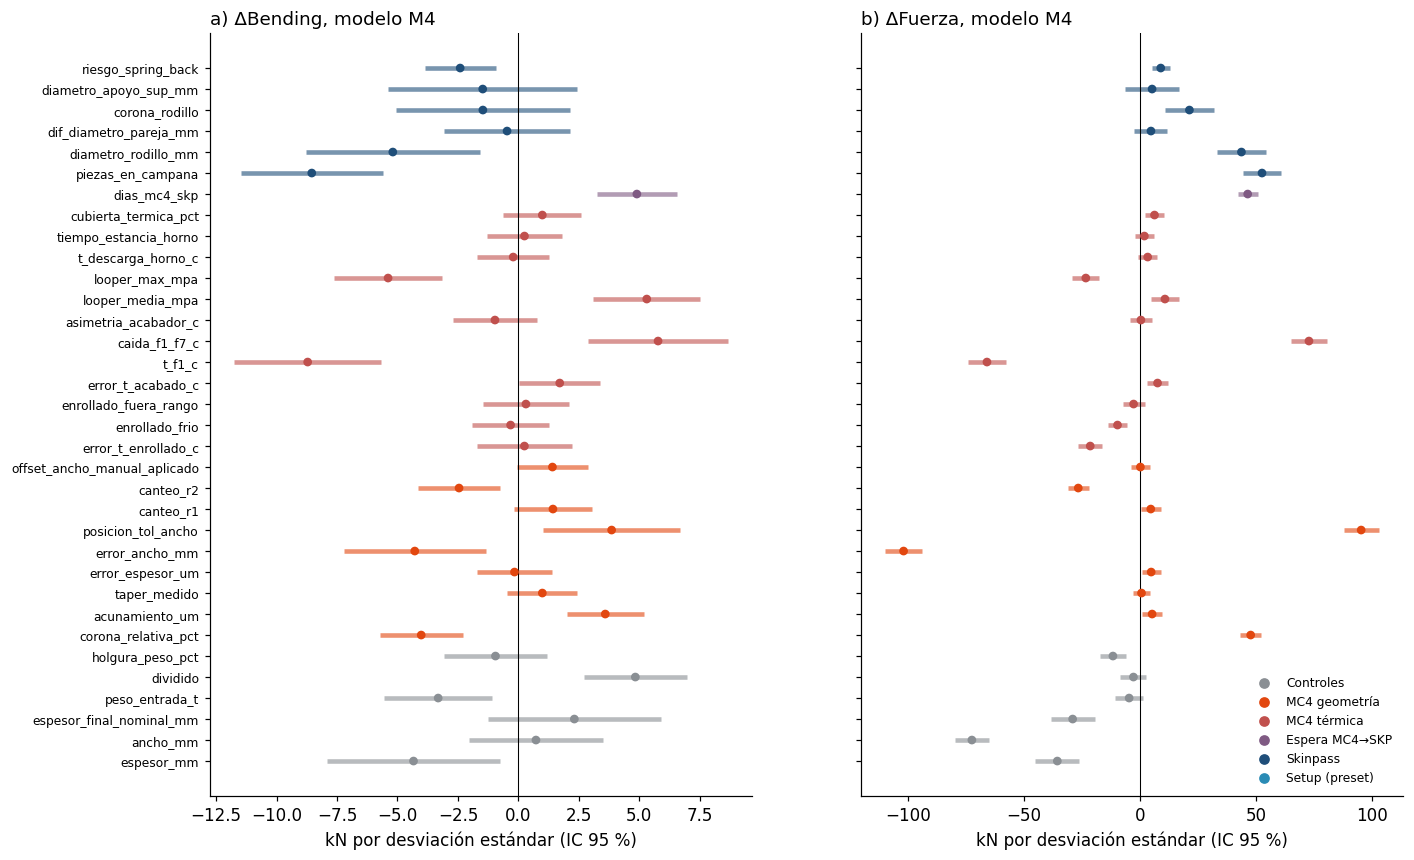

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 9), sharey=True)
COLB = {'Controles': COLORES['gris'], 'MC4 geometría': COLORES['naranja'], 'MC4 térmica': COLORES['rojo'],
        'Espera MC4→SKP': '#7f5a83', 'Skinpass': COLORES['azul'], 'Setup (preset)': '#2a8bb5'}
vars_plot = [c for c in CONTROLES + MC4 + SKP if c not in CONSTANTES]
coef_tab = []
for k, r in enumerate(['delta_bending', 'delta_fuerza']):
    m = lmm_fit[(r, 'M4 completo + interacciones')]
    ci = m.conf_int()
    cf = pd.DataFrame({'coef': m.fe_params, 'bajo': ci[0], 'alto': ci[1]}).loc[vars_plot]
    cf['bloque'] = cf.index.map(BLOQUE)
    coef_tab.append(cf.assign(respuesta=NOMBRE[r]))
    y = np.arange(len(cf))
    ax[k].hlines(y, cf.bajo, cf.alto, color=[COLB[b] for b in cf.bloque], lw=3, alpha=.6)
    ax[k].scatter(cf.coef, y, color=[COLB[b] for b in cf.bloque], s=22, zorder=3)
    ax[k].axvline(0, color='k', lw=.7)
    ax[k].set_yticks(y); ax[k].set_yticklabels(cf.index, fontsize=8)
    ax[k].set_xlabel('kN por desviación estándar (IC 95 %)'); ax[k].set_title(f'{"ab"[k]}) {NOMBRE[r]}, modelo M4')
for b, c in COLB.items(): ax[1].scatter([], [], color=c, label=b)
ax[1].legend(fontsize=8, loc='lower right')
guardar(fig, '04_lmm_coeficientes'); plt.show()
pd.concat(coef_tab).round(2).to_csv(RESULTADOS / '04_lmm_coeficientes.csv')

### 3. GBDT anidados con validación cruzada por programa del MC4
Las variables se usan **sin centrar**: el producto entra como variable categórica en los controles, y el modelo aprende sus propias no linealidades. El R² es **fuera de muestra**.

In [9]:
PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=SEMILLA, verbose=-1)
g = d.copy()
for c in ['producto', 'usuario_skp']:
    g[c] = g[c].astype('category')

def columnas(resp, bloques):
    cols = ['producto'] + CONTROLES
    if 'M' in bloques: cols += MC4
    if 'S' in bloques: cols += SKP + ['usuario_skp'] + ([PRESET[resp]] if resp in REALES else [])
    return cols

def oof(resp, cols):
    pred = np.full(len(g), np.nan)
    for k in range(5):
        tr, va = g['pliegue'] != k, g['pliegue'] == k
        mdl = lgb.LGBMRegressor(**PARAMS).fit(g.loc[tr, cols], g.loc[tr, resp])
        pred[va.values] = mdl.predict(g.loc[va, cols])
    return pred

def media_producto_oof(resp):
    # Referencia justa: la media del producto calculada en los otros pliegues (lo que sabríamos solo con el producto).
    base = np.full(len(g), np.nan)
    for k in range(5):
        tr, va = g['pliegue'] != k, g['pliegue'] == k
        mp = g.loc[tr].groupby('producto', observed=True)[resp].mean()
        base[va.values] = g.loc[va, 'producto'].map(mp).astype(float).fillna(g.loc[tr, resp].mean()).values
    return base

media_prod = {r: media_producto_oof(r) for r in RESPUESTAS}
filas, preds = [], {}
for r in RESPUESTAS:
    y = g[r].values
    for nombre, bl in {'M1 controles': 'C', 'M2 + MC4': 'CM', 'M3 + Skinpass': 'CS', 'M4 completo': 'CMS'}.items():
        p = oof(r, columnas(r, bl)); preds[(r, nombre)] = p
        sse = ((y - p) ** 2).sum()
        filas.append({'respuesta': NOMBRE[r], 'modelo': nombre,
                      'R² total %': 100 * (1 - sse / ((y - y.mean()) ** 2).sum()),
                      'R² dentro de producto %': 100 * (1 - sse / ((y - media_prod[r]) ** 2).sum()),
                      'RMSE kN': np.sqrt(sse / len(y))})
tab_gb = pd.DataFrame(filas)
tab_gb.round(2).to_csv(RESULTADOS / '04_gbdt_anidados.csv', index=False)
tab_gb.round(1)

,respuesta,modelo,R² total %,R² dentro de producto %,RMSE kN
0,ΔBending,M1 controles,1.5,-0.8,184.2
1,ΔBending,M2 + MC4,3.1,0.9,182.6
2,ΔBending,M3 + Skinpass,25.5,23.8,160.2
3,ΔBending,M4 completo,23.0,21.2,162.9
4,Bending real,M1 controles,20.0,9.9,151.5
5,Bending real,M2 + MC4,22.3,12.6,149.3
6,Bending real,M3 + Skinpass,70.3,66.6,92.2
7,Bending real,M4 completo,69.7,65.9,93.2
8,ΔFuerza,M1 controles,87.4,24.9,450.6
9,ΔFuerza,M2 + MC4,87.7,26.8,444.9


In [10]:
# Aportes propio y compartido (R² dentro de producto, fuera de muestra).
piv = tab_gb.pivot(index='respuesta', columns='modelo', values='R² dentro de producto %')
aportes = pd.DataFrame({
    'controles (M1)': piv['M1 controles'],
    'propio MC4 (M4 − M3)': piv['M4 completo'] - piv['M3 + Skinpass'],
    'propio Skinpass (M4 − M2)': piv['M4 completo'] - piv['M2 + MC4'],
    'compartido': (piv['M2 + MC4'] - piv['M1 controles']) - (piv['M4 completo'] - piv['M3 + Skinpass']),
    'total (M4)': piv['M4 completo'],
}).loc[[NOMBRE[r] for r in RESPUESTAS]]
aportes.round(2).to_csv(RESULTADOS / '04_aportes_por_bloque.csv')
aportes.round(1)

,controles (M1),propio MC4 (M4 − M3),propio Skinpass (M4 − M2),compartido,total (M4)
respuesta,,,,,
ΔBending,-0.8,-2.6,20.3,4.3,21.2
Bending real,9.9,-0.7,53.4,3.3,65.9
ΔFuerza,24.9,1.2,9.7,0.7,36.5
Fuerza real,63.4,0.6,6.9,1.1,72.1


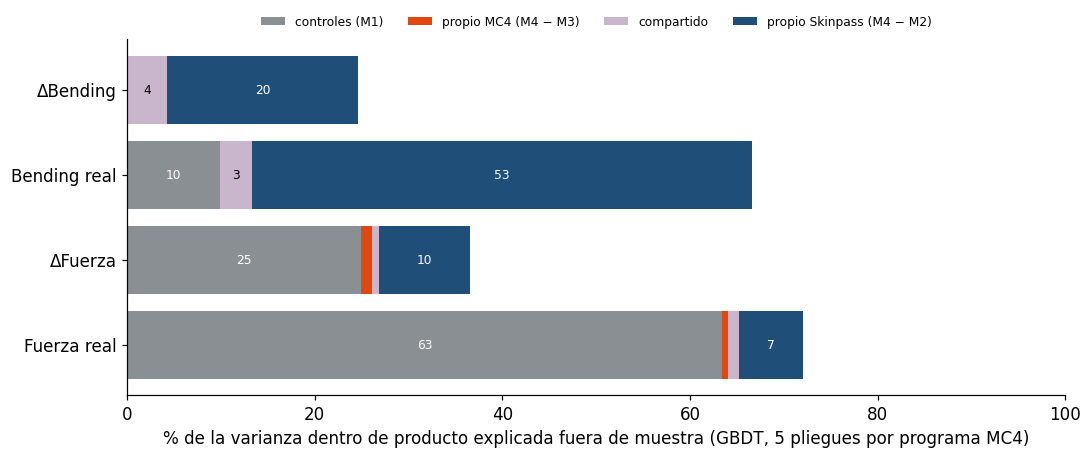

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.2))
orden_r = list(aportes.index)
izq = np.zeros(len(orden_r))
for col, c in [('controles (M1)', COLORES['gris']), ('propio MC4 (M4 − M3)', COLORES['naranja']),
               ('compartido', '#c9b6cc'), ('propio Skinpass (M4 − M2)', COLORES['azul'])]:
    v = aportes[col].clip(lower=0).values
    ax.barh(orden_r, v, left=izq, color=c, label=col)
    for i, (x0, w) in enumerate(zip(izq, v)):
        if w >= 2.5: ax.text(x0 + w / 2, i, f'{w:.0f}', ha='center', va='center', fontsize=8, color='white' if c != '#c9b6cc' else 'black')
    izq += v
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel('% de la varianza dentro de producto explicada fuera de muestra (GBDT, 5 pliegues por programa MC4)')
ax.legend(fontsize=8, ncol=4, loc='lower center', bbox_to_anchor=(.5, 1.0))
guardar(fig, '04_aportes_bloques'); plt.show()

**Cómo leer la gráfica.** Cada barra es una respuesta. Su largo total es el porcentaje de la variación **entre piezas del mismo producto** que el modelo completo predice en piezas que nunca vio:
- **Gris:** los controles (dimensiones, orden y lo que el producto deja dentro de sí).
- **Naranja:** lo que **solo** el MC4 agrega cuando el Skinpass ya está.
- **Azul:** lo que **solo** el Skinpass agrega cuando el MC4 ya está.
- **Lila:** lo compartido, que cualquiera de los dos explica.

El resto, hasta 100, es lo que ningún modelo con estas variables logra predecir.

### 3.1 ¿Explica o memoriza? Validación por campaña de rodillo
Los pliegues agrupan por **programa del MC4**. Pero las piezas de una misma **campaña del Skinpass** pueden quedar en entrenamiento y en validación a la vez. El diámetro del rodillo se registra al montar y es constante en toda la campaña: funciona casi como el "nombre" de la campaña. Un modelo puede aprender "en la campaña con diámetro 431.2 mm el ΔBending es alto" y acertar en validación **sin explicar nada**: solo reconoce la campaña.

Para separar *explicar* de *memorizar*, repetimos la validación con pliegues **por campaña**: el modelo nunca ve en entrenamiento piezas de la campaña que predice. Probamos también el bloque Skinpass sin el operador y sin los diámetros.

In [12]:
from sklearn.model_selection import GroupKFold
pliegue_campana = np.zeros(len(g), int)
for k, (_, va) in enumerate(GroupKFold(n_splits=5).split(g, groups=g['campana'])):
    pliegue_campana[va] = k

def r2_dentro(resp, cols, pliegues):
    pred, base = np.full(len(g), np.nan), np.full(len(g), np.nan)
    for k in range(5):
        tr, va = pliegues != k, pliegues == k
        pred[va] = lgb.LGBMRegressor(**PARAMS).fit(g.loc[tr, cols], g.loc[tr, resp]).predict(g.loc[va, cols])
        mp = g.loc[tr].groupby('producto', observed=True)[resp].mean()
        base[va] = g.loc[va, 'producto'].map(mp).astype(float).fillna(g.loc[tr, resp].mean()).values
    y = g[resp].values
    return 100 * (1 - ((y - pred) ** 2).sum() / ((y - base) ** 2).sum())

C0 = ['producto'] + CONTROLES
SKP_SIN_OP = SKP
SKP_SIN_DIAM = ['piezas_en_campana', 'riesgo_spring_back', 'usuario_skp']
VARIANTES = {'M1 controles': C0, 'M2 + MC4': C0 + MC4, 'M3 + Skinpass': C0 + SKP + ['usuario_skp'],
             'M3 sin operador': C0 + SKP_SIN_OP, 'M3 sin diámetros': C0 + SKP_SIN_DIAM, 'M4 completo': C0 + MC4 + SKP + ['usuario_skp']}
filas = []
for r in ['delta_bending', 'delta_fuerza']:
    for nombre, cols in VARIANTES.items():
        filas.append({'respuesta': NOMBRE[r], 'modelo': nombre,
                      'pliegues por programa MC4': r2_dentro(r, cols, g['pliegue'].values),
                      'pliegues por campaña': r2_dentro(r, cols, pliegue_campana)})
tab_camp = pd.DataFrame(filas)
tab_camp['diferencia'] = tab_camp['pliegues por programa MC4'] - tab_camp['pliegues por campaña']
tab_camp.round(2).to_csv(RESULTADOS / '04_validacion_por_campana.csv', index=False)
tab_camp.round(1)

,respuesta,modelo,pliegues por programa MC4,pliegues por campaña,diferencia
0,ΔBending,M1 controles,-0.8,-1.5,0.7
1,ΔBending,M2 + MC4,0.9,-0.2,1.1
2,ΔBending,M3 + Skinpass,23.8,11.5,12.3
3,ΔBending,M3 sin operador,12.6,-4.8,17.4
4,ΔBending,M3 sin diámetros,14.1,11.5,2.6
5,ΔBending,M4 completo,21.2,12.2,9.0
6,ΔFuerza,M1 controles,24.9,27.0,-2.0
7,ΔFuerza,M2 + MC4,26.8,27.5,-0.7
8,ΔFuerza,M3 + Skinpass,35.3,24.5,10.8
9,ΔFuerza,M3 sin operador,33.3,23.3,10.0


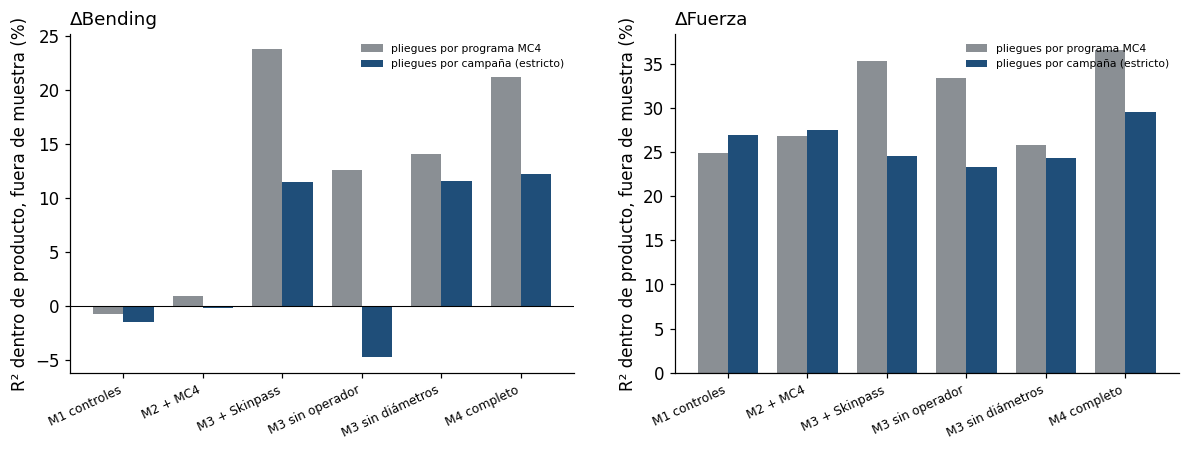

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for a, r in zip(ax, ['ΔBending', 'ΔFuerza']):
    t = tab_camp[tab_camp.respuesta == r].set_index('modelo')
    x = np.arange(len(t)); w = .38
    a.bar(x - w / 2, t['pliegues por programa MC4'], w, color=COLORES['gris'], label='pliegues por programa MC4')
    a.bar(x + w / 2, t['pliegues por campaña'], w, color=COLORES['azul'], label='pliegues por campaña (estricto)')
    a.axhline(0, color='k', lw=.7); a.set_xticks(x); a.set_xticklabels(t.index, rotation=25, ha='right', fontsize=8)
    a.set_ylabel('R² dentro de producto, fuera de muestra (%)'); a.set_title(r); a.legend(fontsize=7)
guardar(fig, '04_validacion_campana'); plt.show()

### 3.2 El operador del Skinpass
Si el operador es lo que generaliza, conviene verlo directamente: ΔBending medio por operador, comparando piezas del mismo producto.

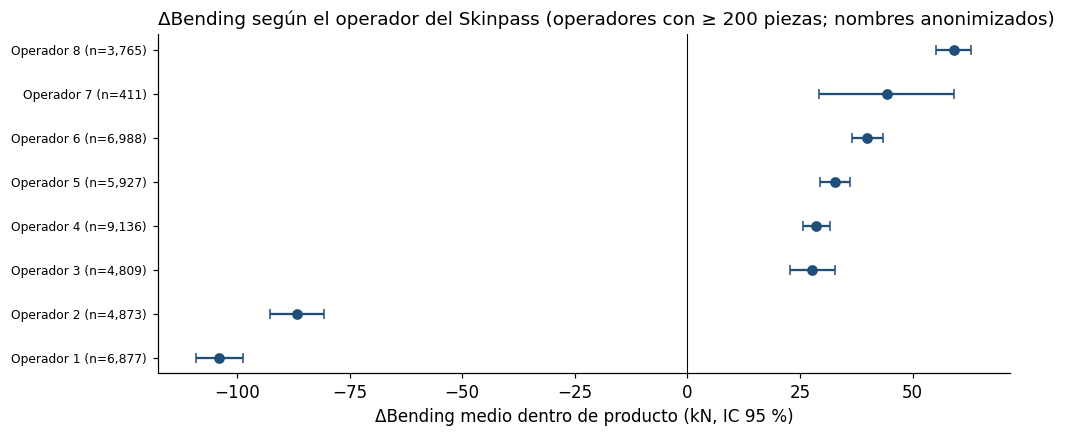

Rango entre operadores: -104 a 59 kN · DE de ΔBending dentro de producto: 177 kN


In [14]:
op = d.assign(db=dentro(d, 'delta_bending'), df_=dentro(d, 'delta_fuerza'))
t_op = op.groupby('usuario_skp').agg(piezas=('db', 'size'), dBending=('db', 'mean'), ee_b=('db', lambda s: s.std() / np.sqrt(len(s))),
                                     dFuerza=('df_', 'mean'))
t_op = t_op[t_op.piezas >= 200].sort_values('dBending')
t_op.index = [f'Operador {i + 1}' for i in range(len(t_op))]      # se anonimiza: la clave de usuario es dato personal
t_op.round(1).to_csv(RESULTADOS / '04_operador.csv')
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(t_op))
ax.errorbar(t_op.dBending, y, xerr=1.96 * t_op.ee_b, fmt='o', color=COLORES['azul'], capsize=3)
ax.axvline(0, color='k', lw=.7)
ax.set_yticks(y); ax.set_yticklabels([f'Operador {i + 1} (n={n:,})' for i, n in enumerate(t_op.piezas)], fontsize=8)
ax.set_xlabel('ΔBending medio dentro de producto (kN, IC 95 %)')
ax.set_title('ΔBending según el operador del Skinpass (operadores con ≥ 200 piezas; nombres anonimizados)')
guardar(fig, '04_operador'); plt.show()
print(f"Rango entre operadores: {t_op.dBending.min():.0f} a {t_op.dBending.max():.0f} kN · DE de ΔBending dentro de producto: {op.db.std():.0f} kN")

### 4. SHAP por bloque en el modelo completo
Entrenamos el modelo completo con todo el entrenamiento y explicamos una muestra de 4,000 piezas.

In [15]:
imp_bloque, imp_var, shap_guardado = {}, {}, {}
muestra = g.sample(4000, random_state=SEMILLA).index
for r in ['delta_bending', 'delta_fuerza']:
    cols = columnas(r, 'CMS')
    mdl = lgb.LGBMRegressor(**PARAMS).fit(g[cols], g[r])
    sv = shap.TreeExplainer(mdl).shap_values(g.loc[muestra, cols])
    m_abs = pd.Series(np.abs(sv).mean(axis=0), index=cols)
    imp_var[r] = m_abs.sort_values(ascending=False)
    imp_bloque[r] = m_abs.groupby(m_abs.index.map(BLOQUE)).sum()
    shap_guardado[r] = (pd.DataFrame(sv, columns=cols, index=muestra), cols)
tab_shap = pd.DataFrame({NOMBRE[r]: 100 * v / v.sum() for r, v in imp_bloque.items()}).round(1)
tab_shap.to_csv(RESULTADOS / '04_shap_bloques.csv')
tab_shap

,ΔBending,ΔFuerza
Controles,27.5,74.8
Espera MC4→SKP,4.3,4.7
MC4 geometría,9.7,3.0
MC4 térmica,8.5,8.5
Skinpass,50.0,9.0


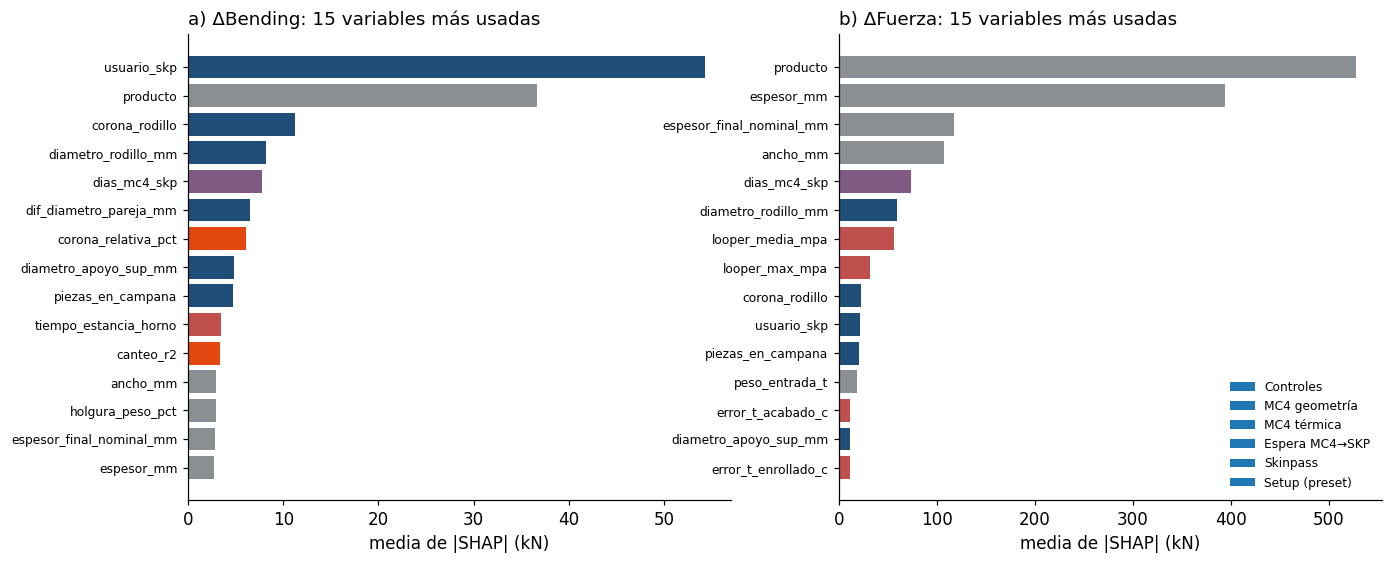

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k, r in enumerate(['delta_bending', 'delta_fuerza']):
    t = imp_var[r].head(15)[::-1]
    ax[k].barh(t.index, t.values, color=[COLB[BLOQUE[c]] for c in t.index])
    ax[k].set_xlabel('media de |SHAP| (kN)'); ax[k].set_title(f'{"ab"[k]}) {NOMBRE[r]}: 15 variables más usadas')
    ax[k].tick_params(axis='y', labelsize=8)
for b, c in COLB.items(): ax[1].barh([], [], color=c, label=b)
ax[1].legend(fontsize=8, loc='lower right')
guardar(fig, '04_shap_variables'); plt.show()

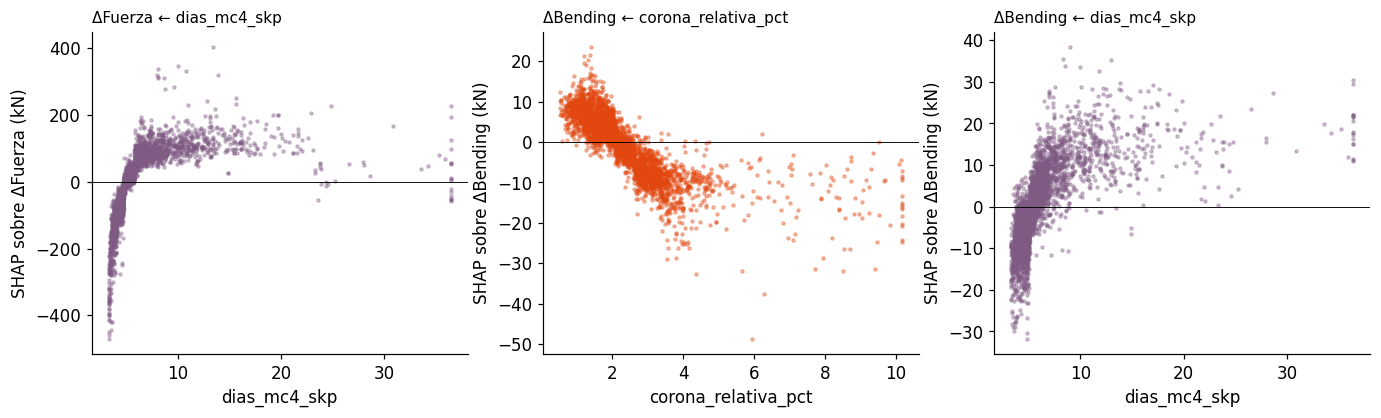

In [17]:
# Dependencia: cómo cambia la contribución de las variables del MC4 más usadas.
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
casos = [('delta_fuerza', 'dias_mc4_skp'), ('delta_bending', 'corona_relativa_pct'), ('delta_bending', 'dias_mc4_skp')]
for a, (r, v) in zip(ax, casos):
    sv, cols = shap_guardado[r]
    x = g.loc[sv.index, v]
    a.scatter(x, sv[v], s=4, alpha=.35, color=COLB[BLOQUE[v]])
    a.axhline(0, color='k', lw=.6)
    a.set_xlabel(v); a.set_ylabel(f'SHAP sobre {NOMBRE[r]} (kN)'); a.set_title(f'{NOMBRE[r]} ← {v}', fontsize=10)
guardar(fig, '04_shap_dependencia'); plt.show()

## E. Interpretación de los resultados

**1. El preset no se puede usar para explicar el Δ (sección 1.1).** Una primera versión de este notebook mostraba al Skinpass explicando el 73 % de ΔBending. Era el preset, que forma parte de la respuesta. Corregido el diseño, las cifras bajan mucho. Es la advertencia más importante del notebook: **un R² alto puede ser aritmética, no proceso**.

**2. Las agrupaciones pesan más que todas las variables (sección 2.1).** Dentro de producto:
- El **programa del Skinpass** concentra el 24 % de la varianza de ΔBending y el 32 % de ΔFuerza.
- La **campaña de rodillo**, el 25 % y el 21 %.
- El **programa del MC4**, solo el 9 % y el 19 %.

Las piezas procesadas juntas en el Skinpass se parecen más entre sí que las laminadas juntas en el MC4.

**3. El MC4 casi no aporta (secciones 2.2, 3 y 3.1).**
- **ΔBending:** el MC4 sube el R² marginal del LMM de 0.15 % a 0.48 %. En GBDT agrega ~1 punto, y con validación por campaña nada (−0.2 %). Su aporte propio sobre el Skinpass es negativo: agregarlo empeora la predicción fuera de muestra.
- **ΔFuerza:** el MC4 sube el R² marginal de 4.8 % a 9.1 % en el LMM (sobre todo por los días de espera), pero en GBDT agrega solo ~2 puntos con pliegues por programa MC4 y ~0.5 con pliegues por campaña.

**4. El Skinpass aporta, pero hay que separar explicar de memorizar (sección 3.1).**
- Con pliegues por programa MC4, el bloque Skinpass explica el 23.8 % de ΔBending dentro de producto. Con pliegues por **campaña**, el 11.5 %.
- La diferencia viene de los **diámetros**: identifican la campaña y permiten "recordar" su nivel.
- Lo que sí generaliza a campañas nuevas es el **operador**: sin él, el bloque cae a −4.8 %.
- Para ΔFuerza, con pliegues por campaña, el Skinpass no agrega nada sobre los controles (24.5 % contra 27.0 %).

**5. El operador (sección 3.2).** Comparando piezas del mismo producto, dos operadores (27 % de las piezas) trabajan con un ΔBending medio de −104 y −87 kN. Los otros seis, entre +28 y +59 kN: una brecha de ~140 kN, comparable con la dispersión típica de ΔBending (DE 177 kN). Parecen **dos prácticas de operación distintas** del bending.
- *Qué no podemos afirmar:* que sea el operador y no el turno o el periodo en que trabaja. Los operadores no se asignan al azar. Aun así es la señal más accionable del problema A.

**6. SHAP (sección 4).** En el modelo completo de ΔBending, el 50 % de la importancia es del bloque Skinpass, el 27 % de los controles y el ~23 % del MC4 (geometría 10, térmica 9, espera 4). En ΔFuerza, los controles dominan (75 %). La importancia del MC4 en SHAP es mayor que su aporte en R² porque SHAP mide **en qué se apoya** el modelo, no **cuánto mejora** la predicción fuera de muestra. Variables del MC4 con mucho ruido se usan para dividir árboles sin generalizar.

## F. Conclusiones de la etapa

### Respuesta a la pregunta de la tesis (parte A)
> **Una vez controlado por producto, la herencia geométrica y térmica del MC4 explica muy poco del esfuerzo del Skinpass**: menos de 1 punto de R² fuera de muestra en ΔBending y ~1-2 en ΔFuerza. La variación del esfuerzo se explica sobre todo por **cómo se opera el Skinpass**: el programa y la campaña (21-32 % de la varianza) y, de forma que sí generaliza, el **operador** (~12 % de ΔBending).

### Hallazgos principales
1. **Acoplamiento Δ-preset:** el preset no puede ser predictor del Δ. Corregido, el Skinpass baja de 73 % a 12-24 % en ΔBending.
2. **El bending real se satura** cuando el preset pide más de ~150 kN sobre lo normal: la intervención B tiene un techo.
3. **Agrupaciones del Skinpass** (programa, campaña): 21-32 % de la varianza dentro de producto, más que todas las variables medidas.
4. **El operador** marca una diferencia de ~140 kN en ΔBending entre dos grupos de práctica.
5. **El MC4 casi no aporta** fuera de muestra, con ninguna de las dos validaciones.
6. **Los diámetros memorizan la campaña:** sin validación por campaña, el Skinpass parece el doble de importante.

### Decisiones tomadas
| Tema | Decisión |
|---|---|
| Preset | Fuera de los modelos de Δ; bloque "Setup" solo para los valores reales |
| Validación del bloque Skinpass | Reportar siempre también la validación por campaña |
| Intervención B | Antes de proponerla, entender la saturación del bending real |
| Nueva línea | Diferencias entre operadores (práctica de operación), candidata a intervención E |

### Limitaciones
- El LMM usa un efecto aleatorio a la vez (statsmodels); los programas MC4 y SKP están cruzados.
- Operador, turno y periodo se confunden entre sí: no hay asignación al azar.
- El periodo de prueba (noviembre-diciembre) sigue sin usarse; se usará al final.

### Qué sigue
El **Notebook 05** (retenciones) prueba si estos mismos bloques explican B1 y B2. Con lo visto en el 02, la familia **forma** es la más prometedora, a través de la **fuerza real**.